# Лабораторная работа № 5 — Классификация
М.А. Мотовилов, группа 4415. Вариант 4 — кредитные данные.

**Цель:** изучение методов классификации на практике. Были исследованы kNN,
дерево решений, логистическая регрессия и случайный лес. Были выполнены все
10 основных пунктов методички. Дополнительно выполнены назначенные задания **14, 13, 8 и 5** (в конце ноутбука).

## Воспроизведение
Рядом с ноутбуком должен находиться `bank_loan_default.csv`. В Jupyter следует
выполнить все ячейки сверху вниз. В Google Colab файл CSV загружается в текущую
папку через панель файлов. Интернет для вычислений не требуется.

Использованы Python 3.14, numpy 2.5.1, pandas 3.0.3, matplotlib 3.11.1,
seaborn 0.13.2, scikit-learn 1.9.1. При переносе в отдельное окружение:
`pip install numpy pandas matplotlib seaborn scikit-learn jupyter`.
Результаты и графики сохраняются в `results/` и встроены в выполненный ноутбук.
Данные были получены из материалов ЛР5: https://disk.yandex.ru/d/Fd-23uk6T3UqIw.
Методичка: «Лабораторная работа 5. Классификация 2026», с. 20–25.

In [1]:
# 01. Библиотеки и воспроизводимость
from pathlib import Path
import hashlib, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, classification_report)

SEED = 42
ROOT = Path.cwd()
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', font='DejaVu Sans', font_scale=0.95)
pd.set_option('display.max_columns', 20)
def savefig(name):
    plt.savefig(OUT / name, dpi=300, bbox_inches='tight')
    plt.show()
versions = {'Python': platform.python_version(), 'numpy': np.__version__,
    'pandas': pd.__version__, 'sklearn': sklearn.__version__}
display(pd.Series(versions, name='Версия').to_frame())

,Версия
Python,3.14.10
numpy,2.5.1
pandas,3.0.3
sklearn,1.9.1


## 1 Загрузка и описание данных
Был использован `bank_loan_default.csv`: одна строка соответствовала заёмщику.
Целевая переменная `Default` обозначила дефолт по кредиту: 1 — дефолт, 0 — его
отсутствие. Она была исключена из признаков. Идентификатором исходной строки
служил индекс `row_id`; в обучение он не передавался.

Числовые признаки: возраст, годовой доход, сумма кредита, ставка, срок кредита,
кредитный скор и число открытых счетов. Срок в месяцах был обработан как числовой
признак с осмысленными расстояниями. Категориальные признаки: тип занятости,
образование, просрочка 30 дней и тип жилья. Образование было закодировано без
предположения о равных расстояниях между уровнями.

In [2]:
# 02. Загрузка и аудит
data_path = ROOT / 'bank_loan_default.csv'
df = pd.read_csv(data_path)
df.index.name = 'row_id'
target = 'Default'
assert set(df[target].unique()) == {0, 1}
X, y = df.drop(columns=target), df[target].astype(int)
numeric = X.select_dtypes(include='number').columns.tolist()
categorical = X.select_dtypes(exclude='number').columns.tolist()
audit = pd.DataFrame({'Тип': df.dtypes.astype(str),
    'Пропуски': df.isna().sum(), 'Уникальных': df.nunique()})
audit.to_csv(OUT / 'data_audit.csv')
display(df.head())
display(audit)
display(pd.Series({'Строк': len(df), 'Столбцов': df.shape[1],
    'Полных дубликатов': int(df.duplicated().sum()),
    'Пропусков': int(df.isna().sum().sum()),
    'SHA256': hashlib.sha256(data_path.read_bytes()).hexdigest()}, name='Аудит').to_frame())
df.describe(include='all').to_csv(OUT / 'descriptive_statistics.csv')

,age,annual_income,employment_type,education,loan_amount,interest_rate_pct,term_months,credit_score,num_open_accounts,delinquency_30d,residence_type,Default
row_id,,,,,,,,,,,,
0,42,57272.0,Self-Employed,Masters,8516.0,5.85,48,730.0,10,No,Own,0
1,51,45786.0,Salaried,Masters,13760.0,9.97,36,677.0,7,No,Mortgage,0
2,69,42359.0,Salaried,Bachelors,2569.0,13.75,48,624.0,2,No,Own,0
3,65,50709.0,Self-Employed,Masters,13204.0,8.70,48,698.0,3,No,Rent,0
4,30,46272.0,Salaried,HS,7700.0,7.53,48,532.0,7,No,Rent,0


,Тип,Пропуски,Уникальных
age,int64,0,54
annual_income,float64,0,2939
employment_type,str,0,3
education,str,0,4
loan_amount,float64,0,2801
interest_rate_pct,float64,0,1214
term_months,int64,0,5
credit_score,float64,0,353
num_open_accounts,int64,0,15
delinquency_30d,str,0,2


,Аудит
Строк,3041
Столбцов,12
Полных дубликатов,0
Пропусков,0
SHA256,ac9181e55be37a2436df8eff1a5fb3fe09c6bbb253540a...


## 2 Предварительная обработка и целевая переменная
Проверялись типы, пропуски, полные дубликаты и диапазоны признаков. Большие суммы
доходов и кредитов были сохранены: высокое значение само по себе не доказывало
ошибку. Удаление наблюдений по целевой переменной не выполнялось.

На матрице диаграмм рассеяния были показаны все семь числовых признаков.
Классы были выделены цветом. Это описательная визуализация всех данных;
отбор признаков и параметров по тестовой выборке не проводился.

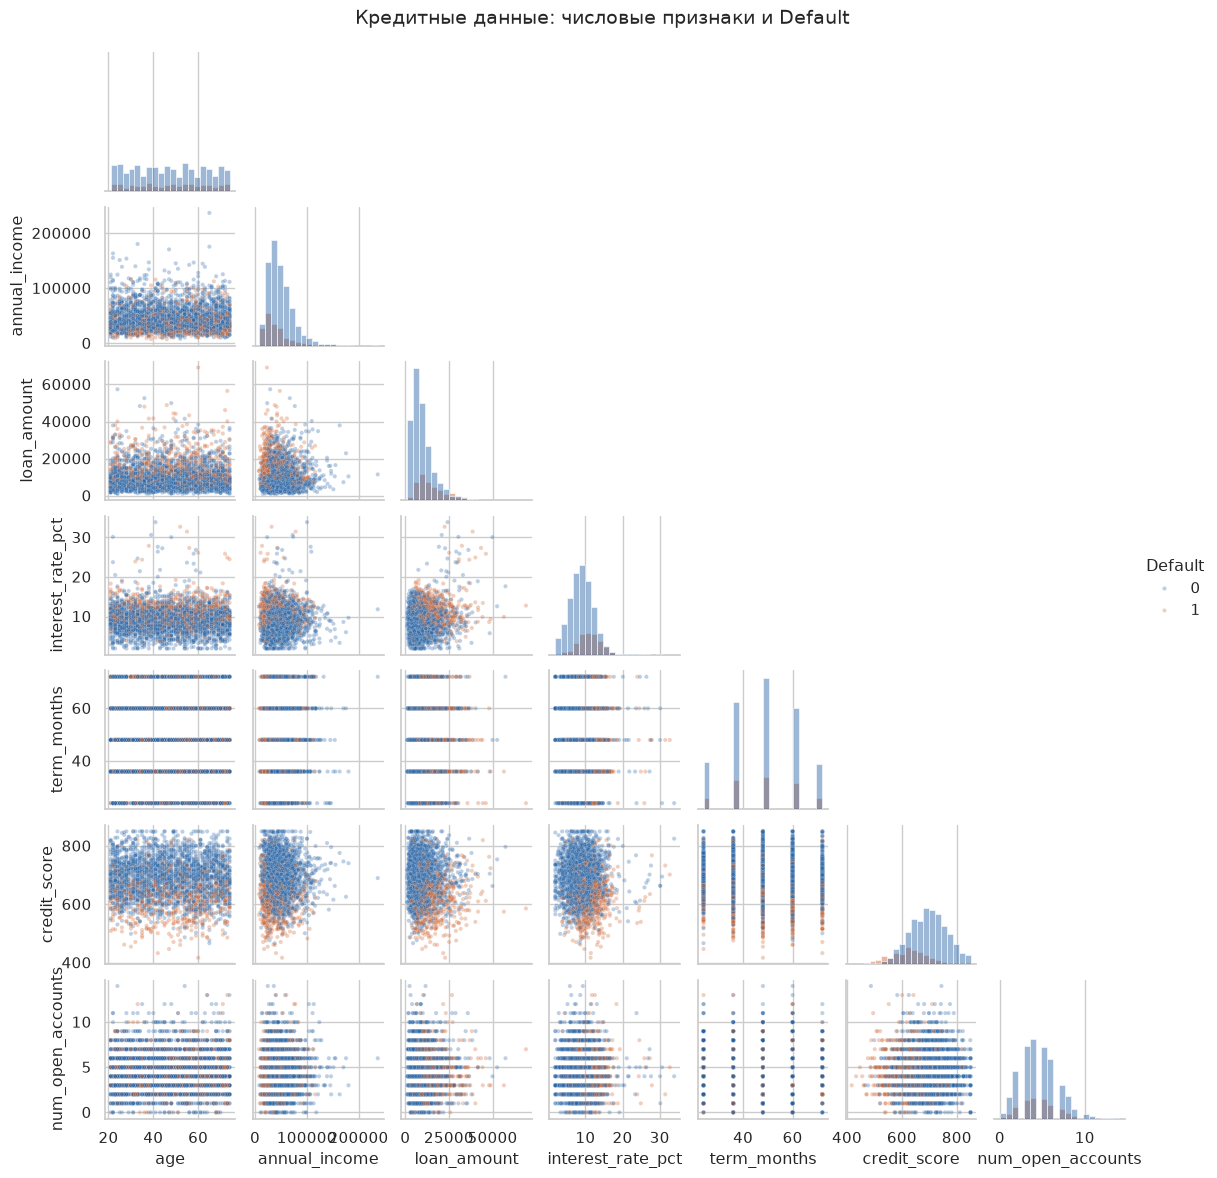

In [3]:
# 03. Матрица диаграмм рассеяния
g = sns.pairplot(df[numeric + [target]], hue=target, diag_kind='hist',
    corner=True, height=1.65, plot_kws={'s': 9, 'alpha': 0.3},
    diag_kws={'bins': 20, 'alpha': 0.45}, palette={0: '#2563a6', 1: '#d16029'})
g.fig.suptitle('Кредитные данные: числовые признаки и Default', y=1.02)
g.savefig(OUT / '01_scatter_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

## 3 Баланс классов и стратегия оценки
Доля дефолтов была сопоставлена с долей кредитов без дефолта. Для несбалансированной
выборки одной Accuracy недостаточно: классификатор, всегда отвечавший 0,
получал высокую долю верных ответов, но не обнаруживал дефолты.

Для выбора параметров использовалась Balanced accuracy — среднее Recall двух
классов. Для дерева, леса и логистической регрессии при перекрёстной проверке
сравнивались варианты с весами классов и без них. В kNN встроенных весов классов
нет; подбирались число соседей и способ взвешивания расстояний. Искусственные
объекты не добавлялись. Разделение и перекрёстная проверка были стратифицированы.

,Количество,Доля
Default,,
0,2421,0.79612
1,620,0.20388


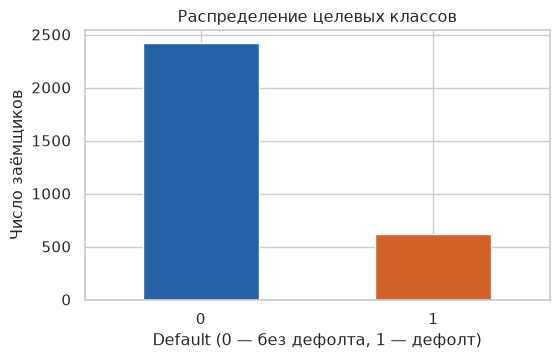

In [4]:
# 04. Баланс классов
balance = y.value_counts().sort_index().rename('Количество').to_frame()
balance['Доля'] = balance['Количество'] / len(y)
balance.to_csv(OUT / 'class_balance.csv')
display(balance)
ax = balance['Количество'].plot.bar(color=['#2563a6', '#d16029'], rot=0, figsize=(6, 3.5))
ax.set(xlabel='Default (0 — без дефолта, 1 — дефолт)', ylabel='Число заёмщиков',
       title='Распределение целевых классов')
savefig('02_class_balance.png')

## 4 Разделение и подготовка признаков
Были выделены 70 % объектов для обучения и 30 % для итоговой проверки,
`random_state=42`, `stratify=y`. Одна и та же тестовая выборка использовалась
для четырёх методов. Поиск параметров проводился только на обучающей части,
с пятью стратифицированными разбиениями, перемешиванием и фиксированным seed.

Числовые признаки прошли заполнение медианой и StandardScaler;
категориальные — заполнение модой и OneHotEncoder с `handle_unknown='ignore'`.
Все преобразования были помещены в Pipeline: средние, масштабы и категории
определялись только на обучающей части каждого разбиения. Для деревьев
масштабирование не обязательно; общая схема упростила сравнение и не изменила
порядок значений признаков. `Default` в ColumnTransformer не передавался.

In [5]:
# 05. Разделение и Pipeline
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y)
preprocess = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scaler', StandardScaler())]), numeric),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical)
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
split = pd.DataFrame({'Часть': ['Обучающая', 'Тестовая'],
    'Объектов': [len(y_train), len(y_test)],
    'Дефолтов': [int(y_train.sum()), int(y_test.sum())],
    'Доля дефолтов': [y_train.mean(), y_test.mean()]})
display(split)
split.to_csv(OUT / 'split_summary.csv', index=False)
assert set(X_train.index).isdisjoint(X_test.index)
assert target not in X_train.columns

,Часть,Объектов,Дефолтов,Доля дефолтов
0,Обучающая,2128,434,0.203947
1,Тестовая,913,186,0.203724


## 5 Обучение четырёх классификаторов
Параметры выбирались по средней Balanced accuracy на пяти обучающих разбиениях.
Во всех случаях порог классификации оставался стандартным — 0,5;
на тестовой выборке порог не подбирался. Сетки были ограничены для быстрого
воспроизведения и не представляли исчерпывающую оптимизацию.

Для kNN сравнивались 5, 11, 21 и 41 сосед; для дерева — глубины 3, 5, 8 и без
ограничения, минимум 5 или 20 объектов в листе; для логистической регрессии —
`C=0.1, 1, 10`; для леса из 200 деревьев — глубины 6 и без ограничения,
минимум 2 или 8 объектов в листе. Для трёх последних методов сравнивались
два режима весов классов. Выбранная модель определялась до расчёта тестовых метрик.

In [6]:
# 06. Поиск параметров на обучающей выборке
specs = {
    'kNN': (KNeighborsClassifier(), {
        'model__n_neighbors': [5, 11, 21, 41], 'model__weights': ['uniform', 'distance']}),
    'Дерево решений': (DecisionTreeClassifier(random_state=SEED), {
        'model__max_depth': [3, 5, 8, None], 'model__min_samples_leaf': [5, 20],
        'model__class_weight': [None, 'balanced']}),
    'Логистическая регрессия': (LogisticRegression(max_iter=3000, random_state=SEED), {
        'model__C': [0.1, 1, 10], 'model__class_weight': [None, 'balanced']}),
    'Случайный лес': (RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1), {
        'model__max_depth': [6, None], 'model__min_samples_leaf': [2, 8],
        'model__class_weight': [None, 'balanced_subsample']})
}
models, searches, selection_rows = {}, {}, []
for name, (estimator, grid) in specs.items():
    pipe = Pipeline([('prepare', clone(preprocess)), ('model', estimator)])
    search = GridSearchCV(pipe, grid, scoring='balanced_accuracy', cv=cv,
                          n_jobs=1, refit=True, error_score='raise')
    search.fit(X_train, y_train)
    models[name], searches[name] = search.best_estimator_, search
    result = pd.DataFrame(search.cv_results_)
    result.to_csv(OUT / ('cv_' + {'kNN':'knn', 'Дерево решений':'tree',
        'Логистическая регрессия':'logistic', 'Случайный лес':'forest'}[name] + '.csv'), index=False)
    selection_rows.append({'Метод': name, 'CV Balanced accuracy': search.best_score_,
        'CV std': result.loc[search.best_index_, 'std_test_score'],
        'Параметры': json.dumps(search.best_params_, ensure_ascii=False)})
selection = pd.DataFrame(selection_rows)
selection.to_csv(OUT / 'model_selection.csv', index=False)
chosen = selection.loc[selection['CV Balanced accuracy'].idxmax(), 'Метод']
display(selection)

,Метод,CV Balanced accuracy,CV std,Параметры
0,kNN,0.643178,0.017989,"{""model__n_neighbors"": 5, ""model__weights"": ""d..."
1,Дерево решений,0.747585,0.009541,"{""model__class_weight"": ""balanced"", ""model__ma..."
2,Логистическая регрессия,0.792811,0.013379,"{""model__C"": 0.1, ""model__class_weight"": ""bala..."
3,Случайный лес,0.781773,0.006165,"{""model__class_weight"": ""balanced_subsample"", ..."


## 6 Ошибка классификации и метрики
На отложенных данных были рассчитаны Accuracy, Precision, Recall, Balanced
accuracy и F1 для положительного класса `Default=1`. Ошибка классификации была
определена как `1 − Accuracy`. Дополнительно были рассчитаны ROC AUC и
специфичность `TN/(TN+FP)`. ROC AUC оценивала ранжирование по вероятностям,
остальные показатели зависели от порога 0,5. Показатели были сопоставлены с
DummyClassifier, всегда предсказывавшим наиболее частый класс.

In [7]:
# 07. Итоговые метрики и прогнозы
def metrics(y_true, pred, proba):
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {'Accuracy': accuracy_score(y_true, pred),
        'Ошибка': 1 - accuracy_score(y_true, pred),
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall': recall_score(y_true, pred, zero_division=0),
        'Balanced accuracy': balanced_accuracy_score(y_true, pred),
        'F1': f1_score(y_true, pred, zero_division=0),
        'ROC AUC': roc_auc_score(y_true, proba), 'Specificity': tn / (tn + fp),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)}

rows, predictions, probabilities = [], {}, {}
prediction_frame = X_test.copy()
prediction_frame['Default_true'] = y_test
for i, (name, model) in enumerate(models.items()):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
    predictions[name], probabilities[name] = pred, proba
    rows.append({'Метод': name, **metrics(y_test, pred, proba)})
    prediction_frame[f'model_{i+1}_prediction'] = pred
    prediction_frame[f'model_{i+1}_probability'] = proba
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
rows.append({'Метод': 'Всегда 0', **metrics(y_test, baseline.predict(X_test),
    baseline.predict_proba(X_test)[:, 1])})
scores = pd.DataFrame(rows).set_index('Метод')
scores.to_csv(OUT / 'test_metrics.csv')
prediction_frame.sort_index().to_csv(OUT / 'test_predictions.csv')
display(scores.round(4))
reports = {name: classification_report(y_test, predictions[name], output_dict=True,
    zero_division=0) for name in models}
(OUT / 'classification_reports.json').write_text(json.dumps(reports, ensure_ascii=False, indent=2))

,Accuracy,Ошибка,Precision,Recall,Balanced accuracy,F1,ROC AUC,Specificity,TN,FP,FN,TP
Метод,,,,,,,,,,,,
kNN,0.8160,0.1840,0.6000,0.2903,0.6204,0.3913,0.7528,0.9505,691,36,132,54
Дерево решений,0.7448,0.2552,0.4259,0.7258,0.7377,0.5368,0.7819,0.7497,545,182,51,135
Логистическая регрессия,0.8105,0.1895,0.5230,0.7957,0.8050,0.6311,0.8681,0.8143,592,135,38,148
Случайный лес,0.8488,0.1512,0.6132,0.6989,0.7931,0.6533,0.8667,0.8872,645,82,56,130
Всегда 0,0.7963,0.2037,0.0000,0.0000,0.5000,0.0000,0.5000,1.0000,727,0,186,0


2767

## 7 Матрицы ошибок
Матрицы были рассчитаны на одной тестовой выборке. Строки соответствовали
фактическим классам, столбцы — прогнозам. FN обозначало пропущенный дефолт,
FP — ложную тревогу. В кредитной задаче оба вида ошибок имели значение:
пропуск дефолта повышал кредитный риск, а ложная тревога могла привести к отказу
надёжному заёмщику. Стоимости этих ошибок в исходных данных не задавались.

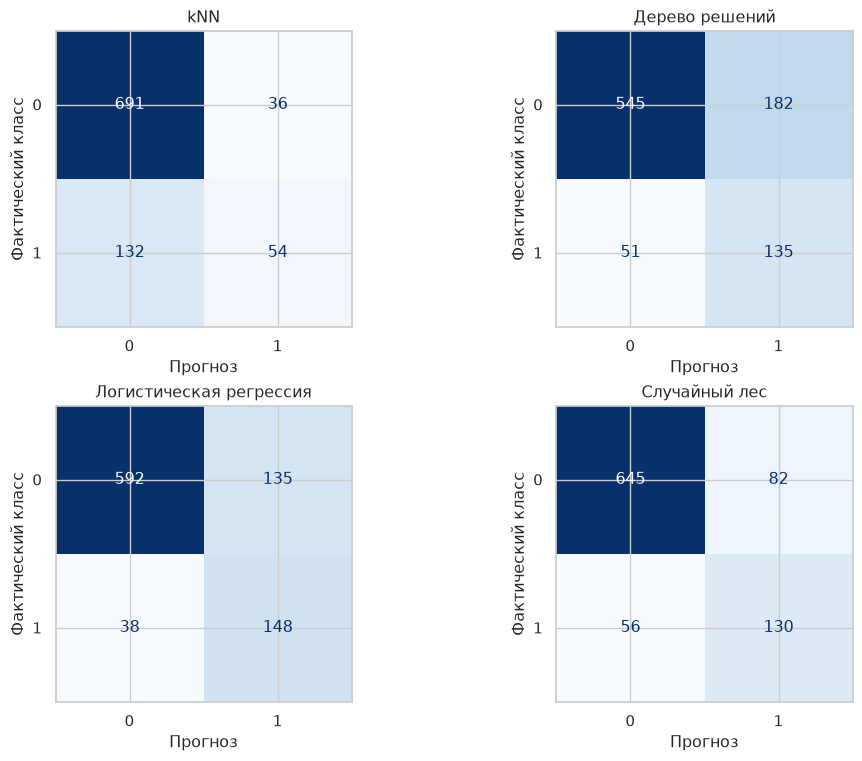

In [8]:
# 08. Матрицы ошибок для всех методов
fig, axes = plt.subplots(2, 2, figsize=(10, 7.5), constrained_layout=True)
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['0', '1']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set(title=name, xlabel='Прогноз', ylabel='Фактический класс')
savefig('03_confusion_matrices.png')

## 8 ROC-кривые и сравнение
ROC-кривые четырёх моделей были нанесены на один график: по горизонтали — доля
ложных тревог FPR, по вертикали — доля обнаруженных дефолтов TPR. Пунктирная
диагональ обозначала случайное ранжирование, а не пятую модель. Для построения
использовались вероятности `predict_proba`, а не готовые метки классов.

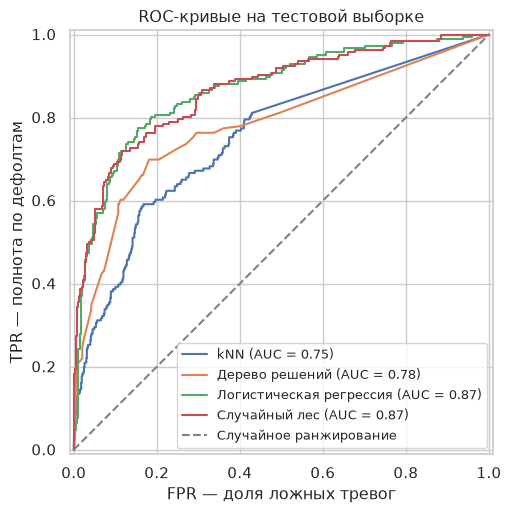

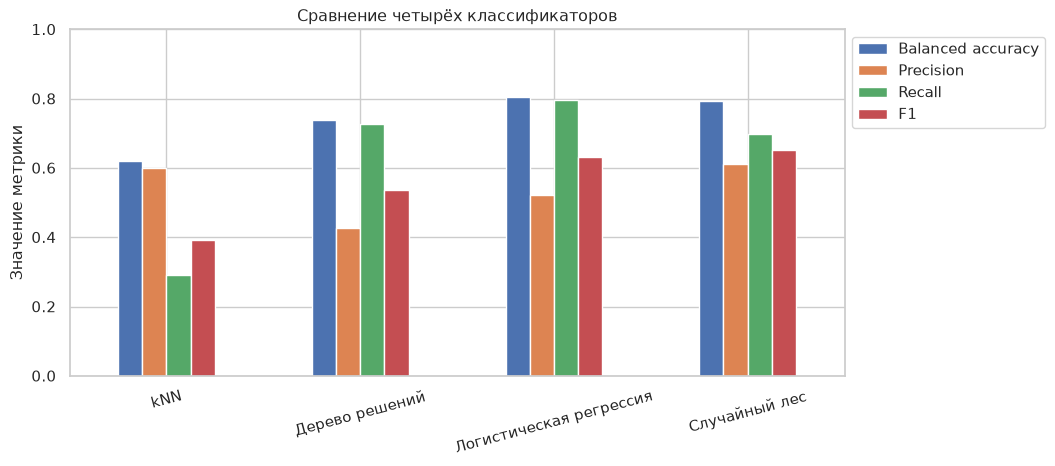

In [9]:
# 09. ROC и сводный график метрик
fig, ax = plt.subplots(figsize=(8, 5.5))
for name, proba in probabilities.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=ax)
ax.plot([0, 1], [0, 1], '--', color='gray', label='Случайное ранжирование')
ax.set(xlabel='FPR — доля ложных тревог', ylabel='TPR — полнота по дефолтам',
       title='ROC-кривые на тестовой выборке')
ax.legend(loc='lower right', fontsize=9)
savefig('04_roc_curves.png')
fig, ax = plt.subplots(figsize=(10, 4.5))
scores.loc[list(models), ['Balanced accuracy', 'Precision', 'Recall', 'F1']].plot.bar(ax=ax, rot=15)
ax.set(ylim=(0, 1), ylabel='Значение метрики', xlabel='', title='Сравнение четырёх классификаторов')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
savefig('05_metrics.png')

## 9 Проверка результатов и сохранение
Сохранены параметры поиска, метрики, прогнозы каждого тестового объекта и графики.
Были проверены непересечение индексов обучающей и тестовой частей, суммы ячеек
матриц ошибок и соответствие Balanced accuracy среднему Recall и Specificity.
Итоговый метод был выбран по CV, до просмотра тестовых результатов.

In [10]:
# 10. Контроль вычислений
for name in models:
    row = scores.loc[name]
    assert int(row[['TN', 'FP', 'FN', 'TP']].sum()) == len(y_test)
    assert np.isclose(row['Balanced accuracy'], (row['Recall'] + row['Specificity']) / 2)
    assert np.isclose(row['Accuracy'], (row['TN'] + row['TP']) / len(y_test))
    assert len(probabilities[name]) == len(y_test)
    assert np.isfinite(probabilities[name]).all()
assert len(X_train) + len(X_test) == len(df)
feature_names = models[chosen].named_steps['prepare'].get_feature_names_out().tolist()
assert not any(target in x for x in feature_names)
summary = {'rows': len(df), 'columns': df.shape[1], 'missing': int(df.isna().sum().sum()),
    'duplicates': int(df.duplicated().sum()), 'numeric': numeric, 'categorical': categorical,
    'encoded_features': feature_names, 'train_rows': len(X_train), 'test_rows': len(X_test),
    'positive': int(y.sum()), 'chosen_by_cv': chosen, 'seed': SEED,
    'sha256': hashlib.sha256(data_path.read_bytes()).hexdigest(), 'versions': versions,
    'model_order': {f'model_{i+1}': name for i, name in enumerate(models)}}
(OUT / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2))
display(pd.Series({'Выбран по CV': chosen, 'Число преобразованных признаков': len(feature_names),
    'Тестовых объектов': len(y_test), 'Проверки': 'Выполнены успешно'}, name='Контроль').to_frame())

,Контроль
Выбран по CV,Логистическая регрессия
Число преобразованных признаков,19
Тестовых объектов,913
Проверки,Выполнены успешно


## 10 Выводы

Была выполнена бинарная классификация дефолта по кредитным данным варианта 4:
3041 заёмщик, 11 исходных признаков и целевая переменная Default. Пропусков и
полных дубликатов не обнаружено. Было сохранено 7 числовых и 4 категориальных
признака; после стандартизации и one-hot-кодирования было получено 19 признаков.
Доля дефолтов составила 20,39 %. Для итоговой проверки было отложено 913 объектов,
в том числе 186 дефолтов; на 2128 объектах проводились обучение и подбор параметров.

По пятичастной CV была выбрана логистическая регрессия с C=0.1 и balanced-весами:
CV Balanced accuracy составила 0,7928 (стандартное отклонение между разбиениями
0,0134). На тесте были получены Balanced accuracy 0,8050, Recall 0,7957,
Precision 0,5230, F1 0,6311 и ROC AUC 0,8681. Были обнаружены 148 из 186 дефолтов,
пропущены 38; ложных тревог было 135. У случайного леса были получены более высокие
Accuracy 0,8488 и F1 0,6533, но более низкая Recall 0,6989: были пропущены 56
дефолтов, ложных тревог было 82. У kNN Recall составила только 0,2903,
у дерева — 0,7258. Таким образом, лидер зависел от выбранного критерия;
преимущество логистической регрессии по ROC AUC над лесом было небольшим
(0,8681 против 0,8667), и статистическая значимость этого различия не проверялась.

Дисбаланс был учтён стратификацией, Balanced accuracy при выборе параметров
и сравнением весов классов внутри CV. Базовый прогноз «всегда 0» дал Accuracy
0,7963, но Recall 0 и Balanced accuracy 0,5, что показало ограниченность одной
Accuracy. Преобразования были обучены внутри Pipeline, тестовая часть не
использовалась для подбора параметров или порога. Выводы были получены для одного
фиксированного разбиения и ограниченных сеток параметров. Стоимость ошибок и
калибровка вероятностей не исследовались; полученные вероятности не трактовались
как откалиброванные оценки кредитного риска.


## Дополнительные задания 14, 13, 8, 5

Используются тот же CSV, разбиение 2128/913 и `random_state=42`, что в основной
части. Класс 1 — дефолт. Все преобразования обучаются внутри Pipeline только
по обучающим данным. `X_valid` ниже — псевдоним уже отложенной `X_test` из
основной части, а не новая выборка. После многократного сравнения на ней
результаты дополнительных опытов следует считать исследовательскими;
для независимого подтверждения выбора нужна новая контрольная выборка.

Таблицы и графики дополнений сохраняются в `results/additional/`.

In [11]:
from sklearn.preprocessing import MinMaxScaler, MaxAbsScaler
from IPython.display import Markdown

EXTRA = OUT / 'additional'
EXTRA.mkdir(exist_ok=True)
X_valid, y_valid = X_test, y_test

def extra_figure(filename):
    plt.savefig(EXTRA / filename, dpi=180, bbox_inches='tight')
    plt.show()

### Задание 14. Accuracy дерева при max_depth от 1 до 16

Для каждой глубины заново обучаем дерево на `X_train` и считаем Accuracy
по `predict(X_train)` и `predict(X_valid)`. Остальные параметры дерева
фиксированы: `criterion='gini'`, `min_samples_leaf=1`, `class_weight=None`.
Это отдельный опыт с глубиной, а не продолжение подбора из основной части.
Рост обучающей Accuracy при ухудшении проверочной и увеличении разрыва
между линиями указывает на переобучение. Лучшая точка проверочной кривой
описывает данный опыт; по ней не выбираем итоговую модель.

,Train Accuracy,Valid Accuracy,Gap
max_depth,,,
1,0.7961,0.7963,-0.0002
2,0.8257,0.8291,-0.0035
3,0.8318,0.8346,-0.0028
4,0.8501,0.8335,0.0166
5,0.8703,0.8335,0.0368
6,0.8900,0.8488,0.0412
7,0.9051,0.8445,0.0606
8,0.9239,0.8269,0.0969
9,0.9417,0.8127,0.1290


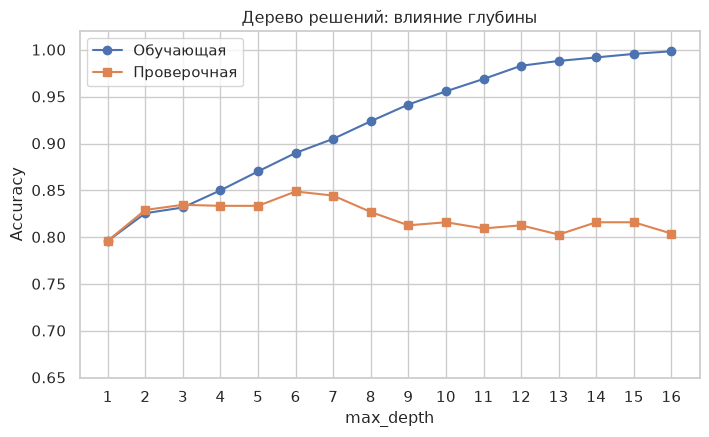

**Результат №14.** Максимальная проверочная Accuracy: 0.8488 при глубине 6. При глубине 1 обучающая/проверочная Accuracy равны 0.7961/0.7963, а при глубине 16 — 0.9986/0.8039; разрыв при глубине 16 составляет 0.1946. Для несбалансированных классов высокую Accuracy нужно также проверять по Recall и TNR.

In [12]:
depth_rows = []
for depth in range(1, 17):
    depth_model = Pipeline([
        ('prepare', clone(preprocess)),
        ('model', DecisionTreeClassifier(max_depth=depth, random_state=SEED))])
    depth_model.fit(X_train, y_train)
    depth_rows.append({'max_depth': depth,
        'Train Accuracy': accuracy_score(y_train, depth_model.predict(X_train)),
        'Valid Accuracy': accuracy_score(y_valid, depth_model.predict(X_valid))})
depth_scores = pd.DataFrame(depth_rows).set_index('max_depth')
depth_scores['Gap'] = depth_scores['Train Accuracy'] - depth_scores['Valid Accuracy']
depth_scores.to_csv(EXTRA / '14_tree_depth_accuracy.csv')
display(depth_scores.round(4))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(depth_scores.index, depth_scores['Train Accuracy'], 'o-', label='Обучающая')
ax.plot(depth_scores.index, depth_scores['Valid Accuracy'], 's-', label='Проверочная')
ax.set(xticks=list(range(1, 17)), xlabel='max_depth', ylabel='Accuracy',
       title='Дерево решений: влияние глубины', ylim=(0.65, 1.02))
ax.legend()
extra_figure('14_tree_depth_accuracy.png')
best_depth = depth_scores['Valid Accuracy'].idxmax()
display(Markdown(
    f'**Результат №14.** Максимальная проверочная Accuracy: '
    f'{depth_scores.loc[best_depth, "Valid Accuracy"]:.4f} при глубине {best_depth}. '
    f'При глубине 1 обучающая/проверочная Accuracy равны '
    f'{depth_scores.loc[1, "Train Accuracy"]:.4f}/{depth_scores.loc[1, "Valid Accuracy"]:.4f}, '
    f'а при глубине 16 — {depth_scores.loc[16, "Train Accuracy"]:.4f}/'
    f'{depth_scores.loc[16, "Valid Accuracy"]:.4f}; разрыв при глубине 16 составляет '
    f'{depth_scores.loc[16, "Gap"]:.4f}. '
    'Для несбалансированных классов высокую Accuracy нужно также проверять по Recall и TNR.'))

### Задание 13. Функция специфичности (TNR)

Специфичность `TNR = TN / (TN + FP)` — доля заёмщиков **без дефолта**,
которых модель правильно отнесла к классу 0. Порядок классов в матрице
ошибок задаём явно: `[0, 1]`. Если в проверяемых данных нет класса 0,
знаменатель равен нулю: возвращаем `NaN`, поскольку TNR не определена.
Функция применяется к четырём моделям основной части без переобучения.

In [13]:
def specificity_tnr(y_true, y_pred):
    """TNR для бинарных меток 0/1; NaN, если нет отрицательных объектов."""
    actual, predicted = np.asarray(y_true), np.asarray(y_pred)
    if actual.ndim != 1 or predicted.ndim != 1 or actual.shape != predicted.shape:
        raise ValueError('Ожидаются одномерные массивы одинаковой длины')
    if not np.isin(actual, [0, 1]).all() or not np.isin(predicted, [0, 1]).all():
        raise ValueError('Метки классов должны быть 0 или 1')
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    return float(tn / (tn + fp)) if tn + fp else float('nan')

# Проверяем известный ответ и случай отсутствия отрицательного класса.
assert specificity_tnr([0, 0, 0, 1], [0, 1, 0, 1]) == 2 / 3
assert specificity_tnr([0, 1], [0, 1]) == 1
assert specificity_tnr([0, 1], [1, 0]) == 0
assert np.isnan(specificity_tnr([1, 1], [0, 1]))

tnr_rows = []
for name, pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_valid, pred, labels=[0, 1]).ravel()
    tnr = specificity_tnr(y_valid, pred)
    assert np.isclose(tnr, scores.loc[name, 'Specificity'])
    assert np.isclose((tnr + recall_score(y_valid, pred)) / 2,
                      balanced_accuracy_score(y_valid, pred))
    tnr_rows.append({'Метод': name, 'TN': tn, 'FP': fp, 'TNR': tnr,
                     'Recall (TPR)': recall_score(y_valid, pred)})
tnr_scores = pd.DataFrame(tnr_rows).set_index('Метод')
tnr_scores.to_csv(EXTRA / '13_specificity.csv')
display(tnr_scores.round(4))
tnr_leader = tnr_scores['TNR'].idxmax()
display(Markdown(
    f'**Результат №13.** Наибольшая специфичность у {tnr_leader}: '
    f'{tnr_scores.loc[tnr_leader, "TNR"]:.4f}, при Recall '
    f'{tnr_scores.loc[tnr_leader, "Recall (TPR)"]:.4f}. '
    'TNR оценивает распознавание класса 0, Recall — класса 1. '
    'Поэтому высокая специфичность сама по себе не означает хорошее обнаружение дефолтов.'))

,TN,FP,TNR,Recall (TPR)
Метод,,,,
kNN,691,36,0.9505,0.2903
Дерево решений,545,182,0.7497,0.7258
Логистическая регрессия,592,135,0.8143,0.7957
Случайный лес,645,82,0.8872,0.6989


**Результат №13.** Наибольшая специфичность у kNN: 0.9505, при Recall 0.2903. TNR оценивает распознавание класса 0, Recall — класса 1. Поэтому высокая специфичность сама по себе не означает хорошее обнаружение дефолтов.

### Задание 8. StandardScaler, MinMaxScaler и MaxAbsScaler

Сравниваем три способа масштабирования **числовых признаков** для каждого из
четырёх методов. StandardScaler центрирует данные и делит на стандартное
отклонение; MinMaxScaler переводит обучающие значения в [0, 1]; MaxAbsScaler
делит на максимальный модуль без центрирования. Значения проверочной части
могут выходить за обучающий диапазон MinMaxScaler — это допустимо.
Категориальные признаки во всех опытах одинаково кодируются OneHotEncoder.

Меняется только scaler: используем параметры моделей, выбранные в основной
части при StandardScaler, без нового подбора. Так сравнивается влияние
масштаба при фиксированной модели, а не максимально достижимое качество
каждой комбинации. Масштабы определяются только по `X_train`.
Для деревьев положительное линейное масштабирование обычно сохраняет
разбиения; kNN и регуляризованная логистическая регрессия чувствительны
к относительным масштабам признаков.

Accuracy  Ошибка  Precision  Recall  \
Метод                   Scaler                                                
kNN                     StandardScaler    0.8160  0.1840     0.6000  0.2903   
                        MinMaxScaler      0.7853  0.2147     0.4306  0.1667   
                        MaxAbsScaler      0.7777  0.2223     0.3692  0.1290   
Дерево решений          StandardScaler    0.7448  0.2552     0.4259  0.7258   
                        MinMaxScaler      0.7448  0.2552     0.4259  0.7258   
                        MaxAbsScaler      0.7448  0.2552     0.4259  0.7258   
Логистическая регрессия StandardScaler    0.8105  0.1895     0.5230  0.7957   
                        MinMaxScaler      0.7788  0.2212     0.4724  0.7366   
                        MaxAbsScaler      0.7864  0.2136     0.4840  0.7312   
Случайный лес           StandardScaler    0.8488  0.1512     0.6132  0.6989   
                        MinMaxScaler      0.8488  0.1512     0.6132  0.6989   
                        MaxAbsScaler      0.8488  0.1512     0.6132  0.6989   

                                        Balanced accuracy      F1  ROC AUC  \
Метод                   Scaler                                               
kNN                     StandardScaler             0.6204  0.3913   0.7528   
                        MinMaxScaler               0.5551  0.2403   0.6405   
                        MaxAbsScaler               0.5363  0.1912   0.6372   
Дерево решений          StandardScaler             0.7377  0.5368   0.7819   
                        MinMaxScaler               0.7377  0.5368   0.7817   
                        MaxAbsScaler               0.7377  0.5368   0.7817   
Логистическая регрессия StandardScaler             0.8050  0.6311   0.8681   
                        MinMaxScaler               0.7631  0.5756   0.8421   
                        MaxAbsScaler               0.7659  0.5824   0.8437   
Случайный лес           StandardScaler             0.7931  0.6533   0.8667   
                        MinMaxScaler               0.7931  0.6533   0.8665   
                        MaxAbsScaler               0.7931  0.6533   0.8666   

                                        Specificity   TN   FP   FN   TP  \
Метод                   Scaler                                            
kNN                     StandardScaler       0.9505  691   36  132   54   
                        MinMaxScaler         0.9436  686   41  155   31   
                        MaxAbsScaler         0.9436  686   41  162   24   
Дерево решений          StandardScaler       0.7497  545  182   51  135   
                        MinMaxScaler         0.7497  545  182   51  135   
                        MaxAbsScaler         0.7497  545  182   51  135   
Логистическая регрессия StandardScaler       0.8143  592  135   38  148   
                        MinMaxScaler         0.7895  574  153   49  137   
                        MaxAbsScaler         0.8006  582  145   50  136   
Случайный лес           StandardScaler       0.8872  645   82   56  130   
                        MinMaxScaler         0.8872  645   82   56  130   
                        MaxAbsScaler         0.8872  645   82   56  130   

                                        Δ Balanced accuracy к Standard  
Метод                   Scaler                                          
kNN                     StandardScaler                          0.0000  
                        MinMaxScaler                           -0.0653  
                        MaxAbsScaler                           -0.0841  
Дерево решений          StandardScaler                          0.0000  
                        MinMaxScaler                            0.0000  
                        MaxAbsScaler                            0.0000  
Логистическая регрессия StandardScaler                          0.0000  
                        MinMaxScaler                           -0.0419  
                        MaxAbsScaler                       

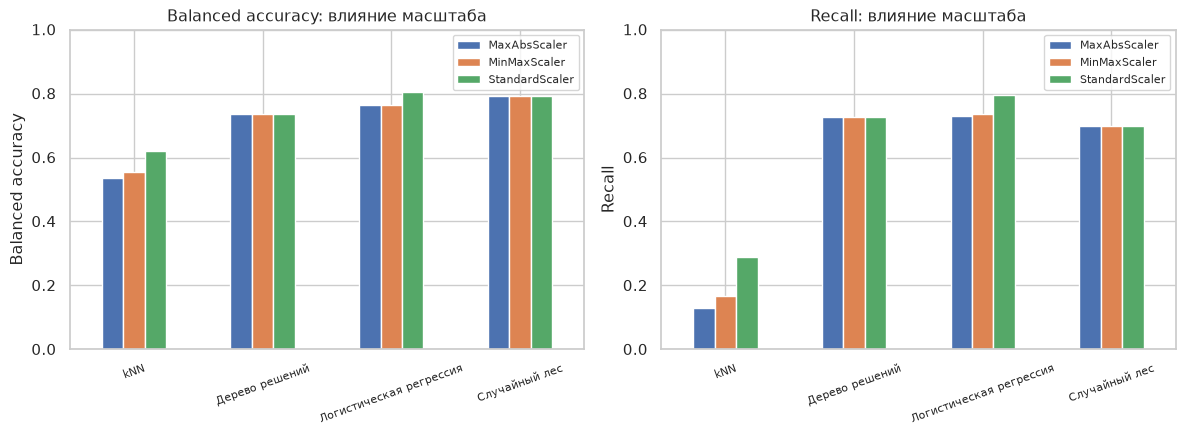

**Результат №8.**

- **kNN**, Balanced accuracy — StandardScaler: 0.6204, MinMaxScaler: 0.5551, MaxAbsScaler: 0.5363.
- **Дерево решений**, Balanced accuracy — StandardScaler: 0.7377, MinMaxScaler: 0.7377, MaxAbsScaler: 0.7377.
- **Логистическая регрессия**, Balanced accuracy — StandardScaler: 0.8050, MinMaxScaler: 0.7631, MaxAbsScaler: 0.7659.
- **Случайный лес**, Balanced accuracy — StandardScaler: 0.7931, MinMaxScaler: 0.7931, MaxAbsScaler: 0.7931.

Метрики StandardScaler совпали с основной частью. Сравнение относится к фиксированным параметрам и одному разбиению; лучший scaler для будущего применения следует выбирать внутри CV.

In [14]:
scalers = {'StandardScaler': StandardScaler(),
           'MinMaxScaler': MinMaxScaler(), 'MaxAbsScaler': MaxAbsScaler()}
scaler_rows = []
for name, fitted_model in models.items():
    for scaler_name, scaler in scalers.items():
        candidate = clone(fitted_model).set_params(prepare__num__scaler=clone(scaler))
        candidate.fit(X_train, y_train)
        pred = candidate.predict(X_valid)
        proba = candidate.predict_proba(X_valid)[:, list(candidate.classes_).index(1)]
        values = metrics(y_valid, pred, proba)
        if scaler_name == 'StandardScaler':
            for metric, value in values.items():
                assert np.isclose(value, scores.loc[name, metric])
        scaler_rows.append({'Метод': name, 'Scaler': scaler_name, **values})
scaler_scores = pd.DataFrame(scaler_rows)
scaler_scores['Δ Balanced accuracy к Standard'] = scaler_scores.apply(
    lambda row: row['Balanced accuracy'] - scores.loc[row['Метод'], 'Balanced accuracy'], axis=1)
scaler_scores.to_csv(EXTRA / '08_scaler_metrics.csv', index=False)
display(scaler_scores.set_index(['Метод', 'Scaler']).round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric in zip(axes, ['Balanced accuracy', 'Recall']):
    scaler_scores.pivot(index='Метод', columns='Scaler', values=metric).plot.bar(ax=ax, rot=20)
    ax.set(ylabel=metric, xlabel='', ylim=(0, 1), title=metric + ': влияние масштаба')
    ax.tick_params(axis='x', labelsize=8)
    ax.legend(fontsize=8)
fig.tight_layout()
extra_figure('08_scaler_comparison.png')
scale_notes = []
for name in models:
    group = scaler_scores[scaler_scores['Метод'] == name]
    values = ', '.join(f'{row["Scaler"]}: {row["Balanced accuracy"]:.4f}'
                       for _, row in group.iterrows())
    scale_notes.append(f'- **{name}**, Balanced accuracy — {values}.')
display(Markdown('**Результат №8.**\n\n' + '\n'.join(scale_notes) +
    '\n\nМетрики StandardScaler совпали с основной частью. '
    'Сравнение относится к фиксированным параметрам и одному разбиению; '
    'лучший scaler для будущего применения следует выбирать внутри CV.'))

### Задание 5. GridSearchCV для дерева и сравнение параметров

В основной части уже выполнен настоящий GridSearchCV для дерева: 16 сочетаний
`max_depth=[3, 5, 8, None]`, `min_samples_leaf=[5, 20]`,
`class_weight=[None, 'balanced']`, по 5 стратифицированных разбиений.
Здесь используем сохранённый объект поиска `searches['Дерево решений']`:
выводим всю сетку и явно сравниваем выбранное дерево с деревом с другими
параметрами — стандартными `max_depth=None`, `min_samples_leaf=1`,
`class_weight=None`. Оба дерева используют одинаковую предобработку.

Критерий оптимизации — Balanced accuracy, потому что классы несбалансированы.
«Оптимальные» параметры означают лучшие **в пределах этой сетки и CV**.
У выбранной модели показываем также обучающую Accuracy, все итоговые метрики
и разницу относительно стандартного дерева. Проверочная выборка в поиске
параметров не участвует.

In [15]:
tree_search = searches['Дерево решений']
tree_grid = pd.DataFrame(tree_search.cv_results_)[[
    'param_model__max_depth', 'param_model__min_samples_leaf',
    'param_model__class_weight', 'mean_test_score', 'std_test_score', 'rank_test_score']
].sort_values('rank_test_score')
tree_grid.to_csv(EXTRA / '05_tree_grid_search.csv', index=False)
display(tree_grid)
display(Markdown(f'Лучшие параметры: `{tree_search.best_params_}`. '
    f'Средняя CV Balanced accuracy: **{tree_search.best_score_:.4f}**.'))
default_tree = Pipeline([('prepare', clone(preprocess)),
                        ('model', DecisionTreeClassifier(random_state=SEED))])
default_tree.fit(X_train, y_train)
tree_comparison_rows = []
for name, candidate in [('GridSearchCV', tree_search.best_estimator_),
                         ('Стандартные параметры', default_tree)]:
    pred = candidate.predict(X_valid)
    proba = candidate.predict_proba(X_valid)[:, list(candidate.classes_).index(1)]
    tree_comparison_rows.append({'Дерево': name,
        'Train Accuracy': accuracy_score(y_train, candidate.predict(X_train)),
        **metrics(y_valid, pred, proba)})
tree_comparison = pd.DataFrame(tree_comparison_rows).set_index('Дерево')
tree_comparison.to_csv(EXTRA / '05_tree_comparison.csv')
display(tree_comparison.round(4))
delta = tree_comparison.loc['GridSearchCV'] - tree_comparison.loc['Стандартные параметры']
display(Markdown(
    f'**Результат №5.** После подбора проверочная Balanced accuracy '
    f'{tree_comparison.loc["GridSearchCV", "Balanced accuracy"]:.4f} '
    f'(у стандартного дерева {tree_comparison.loc["Стандартные параметры", "Balanced accuracy"]:.4f}, '
    f'разница {delta["Balanced accuracy"]:+.4f}); '
    f'Recall {tree_comparison.loc["GridSearchCV", "Recall"]:.4f} '
    f'(разница {delta["Recall"]:+.4f}), Accuracy '
    f'{tree_comparison.loc["GridSearchCV", "Accuracy"]:.4f} '
    f'(разница {delta["Accuracy"]:+.4f}). '
    'Улучшение оценивается прежде всего по выбранному критерию Balanced accuracy; '
    'другие метрики могут измениться в противоположную сторону. '
    'Статистическая значимость разницы в этом опыте не проверялась.'))

,param_model__max_depth,param_model__min_samples_leaf,param_model__class_weight,mean_test_score,std_test_score,rank_test_score
12,8,5,balanced,0.747585,0.009541,1
15,None,20,balanced,0.745620,0.005662,2
13,8,20,balanced,0.742943,0.006008,3
10,5,5,balanced,0.742827,0.025190,4
11,5,20,balanced,0.739481,0.020091,5
9,3,20,balanced,0.727637,0.017255,6
14,None,5,balanced,0.726749,0.020008,7
8,3,5,balanced,0.724743,0.019176,8
4,8,5,NaN,0.686947,0.023300,9
3,5,20,NaN,0.685586,0.016222,10


Лучшие параметры: `{'model__class_weight': 'balanced', 'model__max_depth': 8, 'model__min_samples_leaf': 5}`. Средняя CV Balanced accuracy: **0.7476**.

,Train Accuracy,Accuracy,Ошибка,Precision,Recall,Balanced accuracy,F1,ROC AUC,Specificity,TN,FP,FN,TP
Дерево,,,,,,,,,,,,,
GridSearchCV,0.8186,0.7448,0.2552,0.4259,0.7258,0.7377,0.5368,0.7819,0.7497,545,182,51,135
Стандартные параметры,1.0000,0.8028,0.1972,0.5165,0.5054,0.6922,0.5109,0.6922,0.8790,639,88,92,94


**Результат №5.** После подбора проверочная Balanced accuracy 0.7377 (у стандартного дерева 0.6922, разница +0.0456); Recall 0.7258 (разница +0.2204), Accuracy 0.7448 (разница -0.0581). Улучшение оценивается прежде всего по выбранному критерию Balanced accuracy; другие метрики могут измениться в противоположную сторону. Статистическая значимость разницы в этом опыте не проверялась.

### Итог дополнительных заданий

Выполнены все четыре назначенных задания: №14 — 16 глубин и две кривые
Accuracy; №13 — отдельная функция TNR и её значения для четырёх методов;
№8 — 12 сочетаний метода и scaler с полным набором метрик; №5 — результаты
GridSearchCV и сравнение со стандартным деревом. Численные выводы формируются
из рассчитанных таблиц в выводах ячеек выше и обновляются при повторном запуске.
Сравнения сохраняют исходное разбиение и исключают обучение предобработки на
проверочной части. Выбор по CV и исследование проверочных кривых имеют разные
цели; новые параметры по проверочным максимумам в основную модель не вносились.